# DSAI Club Induction 2026 — Toxic Comment Classification (SY Task Round)
**Arnav Katepallewar, CSE.** Multi-label problem (6 labels), metric = mean column-wise ROC AUC. Constraints: trained only on `competition_train.csv`, **< 1M parameters**.

**Approach summary**
1. EDA of text and label imbalance
2. Baseline: word TF-IDF + Logistic Regression
3. Improvement 1: add character n-grams
4. Improvement 2: Naive-Bayes feature scaling (NB-LR)
5. Improvement 3: per-label regularisation (C)
6. Improvement 4 (final): large n-gram vocabulary + **per-label chi-squared feature selection** (best 165,000 n-grams per label)
7. Final fit on all training data -> `submission.csv`

Final model: one NB-scaled logistic regression per label on its own 165,000 chi-squared-selected word+char TF-IDF features = 6 x (165,000 + 1) = **990,006 trainable parameters**. Public leaderboard: 0.98667 (stage 4) -> 0.98722 (stage 5) -> **0.98775** (final).

In [1]:
import os, glob, warnings
import pandas as pd, numpy as np, scipy.sparse as sp
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import rankdata
warnings.filterwarnings('ignore')
SMOKE = False   # True = tiny subsample/vocabulary, only to check the notebook runs end-to-end
RUN_CV = False  # True = also run the (slow) 5-fold CV for the 140k-feature stage-5 model
L = ['toxic','severe_toxic','obscene','threat','insult','identity_hate']
# find the data folder on Kaggle, else use the current directory
hits = glob.glob('/kaggle/input/**/competition_train.csv', recursive=True)
D = os.path.dirname(hits[0]) + '/' if hits else ''
OUT = '/kaggle/working/' if hits else ''
tr = pd.read_csv(D+'competition_train.csv'); te = pd.read_csv(D+'competition_test.csv'); ss = pd.read_csv(D+'sample_submission.csv')
if SMOKE:
    tr = tr.sample(6000, random_state=0).reset_index(drop=True); te = te.head(500); ss = ss.head(500)
    K, WMAX, CMAX, GRID = 20000, 20000, 40000, [0.3, 1.0]
else:
    K, WMAX, CMAX, GRID = 165000, 300000, 600000, [0.3, 0.6, 1.0, 1.6, 2.5]
print(tr.shape, te.shape, 'missing values:', tr.isna().sum().sum())

(127657, 8) (31914, 2) missing values: 0


## 1. Exploration

toxic            0.0964
severe_toxic     0.0100
obscene          0.0532
threat           0.0030
insult           0.0493
identity_hate    0.0090
dtype: float64
comments with no label: 0.8977


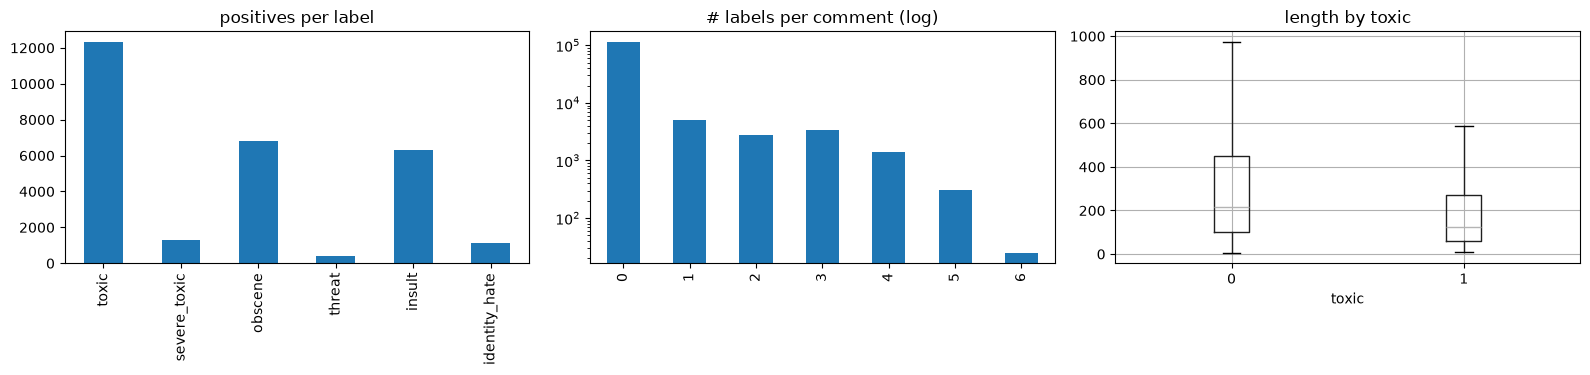

In [2]:
print(tr[L].mean().round(4)); print('comments with no label:', (tr[L].sum(axis=1)==0).mean().round(4))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
tr[L].sum().plot.bar(ax=ax[0], title='positives per label')
tr[L].sum(axis=1).value_counts().sort_index().plot.bar(ax=ax[1], title='# labels per comment (log)', logy=True)
tr['len'] = tr.comment_text.str.len()
tr.boxplot('len', by='toxic', ax=ax[2], showfliers=False); ax[2].set_title('length by toxic'); plt.suptitle(''); plt.tight_layout(); plt.show()

In [3]:
print(tr[L].corr().round(2))
print('severe_toxic that are not toxic:', ((tr.severe_toxic==1)&(tr.toxic==0)).sum())
tr['caps'] = tr.comment_text.apply(lambda s: sum(ch.isupper() for ch in s)/max(len(s),1))
print(tr.groupby('toxic')[['len','caps']].mean())

               toxic  severe_toxic  obscene  threat  insult  identity_hate
toxic           1.00          0.31     0.68    0.16    0.65           0.27
severe_toxic    0.31          1.00     0.40    0.12    0.38           0.20
obscene         0.68          0.40     1.00    0.14    0.74           0.29
threat          0.16          0.12     0.14    1.00    0.15           0.12
insult          0.65          0.38     0.74    0.15    1.00           0.34
identity_hate   0.27          0.20     0.29    0.12    0.34           1.00
severe_toxic that are not toxic: 0


              len      caps
toxic                      
0      404.120621  0.044824
1      293.364922  0.112598


**Findings**
- Heavy imbalance: toxic ~9.6%, obscene ~5.3%, insult ~4.9%, severe_toxic ~1.0%, identity_hate ~0.9%, threat ~0.3%; ~90% of comments have no label.
- Labels are correlated (every severe_toxic is also toxic; obscene/insult/toxic overlap) but not identical -> one model per label.
- Toxic comments are shorter and use more capital letters. Text has obfuscated spellings -> motivates character n-grams.
- **Imbalance handling:** the metric is ROC AUC, which is rank-based and insensitive to the class prior, so I do not resample or reweight; I use stratified splits so rare labels appear in every fold.

## 2. Validation strategy
- **Model comparison and per-label C selection:** stratified 80/20 hold-out (stratified on `toxic`, seed 42). Everything that uses labels (chi-squared selection, NB ratios, classifier) is fitted on the 80% part only.
- **Earlier check:** stratified 5-fold CV for the stage-5 model (optional cell, `RUN_CV`).
- The TF-IDF vocabulary/IDF is fit without labels, on training text only (the test text is never fitted on).
- The final model is re-fit on 100% of the training data.
- Caveat: C is chosen on the same hold-out that is reported, so the hold-out score is slightly optimistic.

In [4]:
a, b = train_test_split(tr, test_size=0.2, random_state=42, stratify=tr.toxic)
def score(P, df=b):
    s = [roc_auc_score(df[l], P[:,i]) for i, l in enumerate(L)]; return np.round(s, 4), round(float(np.mean(s)), 5)

def nb_ratio(A, y):
    p = (A[y==1].sum(axis=0)+1)/((y==1).sum()+1); q = (A[y==0].sum(axis=0)+1)/((y==0).sum()+1)
    return np.asarray(np.log(p/q)).ravel()

def fit_predict(Xa, ya, Xb_list, C_, nb=False):
    # trains ONE label; returns predictions for each matrix in Xb_list and the number of trainable parameters
    r = nb_ratio(Xa, ya) if nb else None
    f = (lambda Z: Z.multiply(r).tocsr()) if nb else (lambda Z: Z)
    m = LogisticRegression(C=C_, solver='liblinear').fit(f(Xa), ya)
    return [m.predict_proba(f(B))[:,1] for B in Xb_list], m.coef_.size + m.intercept_.size

def fit_all(Xa, Xb, C_, nb=False, df=a):
    P = np.zeros((Xb.shape[0], 6)); n = 0
    for i, l in enumerate(L):
        (P[:,i],), k = fit_predict(Xa, df[l].values, [Xb], C_, nb); n += k
    return P, n

## 3. Baseline: word TF-IDF + Logistic Regression

In [5]:
wv0 = TfidfVectorizer(sublinear_tf=True, max_features=50000, strip_accents='unicode', min_df=2)
Xw_a = wv0.fit_transform(a.comment_text); Xw_b = wv0.transform(b.comment_text)
P_base, n = fit_all(Xw_a, Xw_b, 4); print('parameters:', n); print('BASELINE (per-label AUC, mean):', score(P_base))

parameters: 300006
BASELINE (per-label AUC, mean): (array([0.9737, 0.9827, 0.9845, 0.9914, 0.979 , 0.9752]), 0.98107)


## 4. Improvements
### 4a. Add character n-grams (robust to obfuscated / misspelled words)

In [6]:
def make_vecs(w, c, wng=(1,2), cng=(2,5)):
    return (TfidfVectorizer(sublinear_tf=True, ngram_range=wng, max_features=w, strip_accents='unicode', min_df=2),
            TfidfVectorizer(sublinear_tf=True, analyzer='char_wb', ngram_range=cng, max_features=c, min_df=3))
wv, cv = make_vecs(50000, 90000) if not SMOKE else make_vecs(20000, 40000)
Xa = sp.hstack([wv.fit_transform(a.comment_text), cv.fit_transform(a.comment_text)]).tocsr()
Xb = sp.hstack([wv.transform(b.comment_text), cv.transform(b.comment_text)]).tocsr()
P_lr, n = fit_all(Xa, Xb, 2); print('parameters:', n, '(<1M)'); print('word+char LR:', score(P_lr))

parameters: 840006 (<1M)
word+char LR: (array([0.9796, 0.9881, 0.9902, 0.9905, 0.9834, 0.9848]), 0.98608)


### 4b. Naive-Bayes feature scaling (NB-LR)
Each feature is multiplied by the log-count ratio log(p/q) of how often it appears in positive vs negative comments of that label, so the linear model starts from discriminative n-grams. Helps most for rare labels.

In [7]:
P_nb, n = fit_all(Xa, Xb, 0.5, nb=True); print('parameters:', n); print('word+char NB-LR (C=0.5):', score(P_nb))
rk = lambda P: np.column_stack([rankdata(P[:,i])/len(P) for i in range(6)])
print('(experiment) rank-blend LR+NB-LR:', score(0.5*rk(P_lr)+0.5*rk(P_nb)))

parameters: 840006
word+char NB-LR (C=0.5): (array([0.9821, 0.9888, 0.9928, 0.9898, 0.9862, 0.9847]), 0.9874)
(experiment) rank-blend LR+NB-LR: (array([0.9819, 0.9889, 0.9919, 0.9913, 0.9855, 0.9858]), 0.98755)


The blend is only ~+0.0002 better, but it needs two models = ~1.68M parameters in total, which violates the 1M limit, so it is **not used**. A single model is kept.

### 4c. Per-label regularisation (C)
Rare labels (few positives) and the common `toxic` label want different regularisation strengths. In an earlier run I tuned C per label with 5-fold CV for the 140k-feature NB-LR model (CV mean AUC 0.98726 vs 0.98680 for one C=0.5; leaderboard 0.98667 -> 0.98722). The optional cell below reproduces that CV (slow: 120 fits, ~40-80 min), so it is switched off by default (`RUN_CV = False`).

In [8]:
if RUN_CV:
    CV_GRID = [0.15, 0.3, 0.6, 1.0]
    wvF, cvF = make_vecs(50000, 90000)
    X140 = sp.hstack([wvF.fit_transform(tr.comment_text), cvF.fit_transform(tr.comment_text)]).tocsr()
    folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X140, tr.toxic))
    def cv_job(li, C_, fi):
        tri, vai = folds[fi]; (p,), _ = fit_predict(X140[tri], tr[L[li]].values[tri], [X140[vai]], C_, nb=True); return li, C_, fi, p
    res = Parallel(n_jobs=-1)(delayed(cv_job)(li, C_, fi) for li in range(6) for C_ in CV_GRID for fi in range(5))
    oof = {(li, C_): np.zeros(len(tr)) for li in range(6) for C_ in CV_GRID}
    for li, C_, fi, p in res: oof[(li, C_)][folds[fi][1]] = p
    cvtab = pd.DataFrame({C_: [roc_auc_score(tr[L[li]], oof[(li, C_)]) for li in range(6)] for C_ in CV_GRID}, index=L)
    print(cvtab.round(5)); print(cvtab.mean().round(5)); print('CV mean AUC with best C per label: %.5f' % cvtab.max(axis=1).mean())
else:
    print('RUN_CV is False -> skipped (result from my local run: CV mean AUC 0.98726 with per-label C)')

RUN_CV is False -> skipped (result from my local run: CV mean AUC 0.98726 with per-label C)


### 4d. Final improvement: big vocabulary + per-label chi-squared feature selection
The parameter limit is 1M, i.e. at most ~166k weights per label. Instead of keeping the *most frequent* 140k n-grams for every label, I:
1. build a much larger candidate vocabulary (word 1-3 grams, 300k + char 1-6 grams, 600k = 900k candidates),
2. for each label, score every n-gram with a **chi-squared test** against that label and keep the **best 165,000**,
3. apply NB scaling and train the logistic regression on those features.

So each label gets its own most informative n-grams within the same budget: 6 x (165,000 weights + 1 bias) = **990,006** parameters. The candidate vocabulary, IDF values and NB ratios are fixed statistics computed from the data, not trained weights.

In [9]:
def select_idx(Xa, y, k):
    s = np.nan_to_num(chi2(Xa, y)[0]); return np.sort(np.argsort(-s)[:k])

def label_grid(Xa, y, Xb, yb, k):
    idx = select_idx(Xa, y, k); A, B = Xa[:, idx], Xb[:, idx]
    r = nb_ratio(A, y); A, B = A.multiply(r).tocsr(), B.multiply(r).tocsr()
    return [roc_auc_score(yb, LogisticRegression(C=C_, solver='liblinear').fit(A, y).predict_proba(B)[:,1]) for C_ in GRID]

wvB, cvB = make_vecs(WMAX, CMAX, wng=(1,3), cng=(1,6))
XA = sp.hstack([wvB.fit_transform(a.comment_text), cvB.fit_transform(a.comment_text)]).tocsr()
XB = sp.hstack([wvB.transform(b.comment_text), cvB.transform(b.comment_text)]).tocsr()
print('candidate features:', XA.shape[1])
res = Parallel(n_jobs=-1)(delayed(label_grid)(XA, a[l].values, XB, b[l].values, K) for l in L)
tab = pd.DataFrame(res, index=L, columns=GRID)
print(tab.round(5)); print('\nmean AUC for a single C on all labels:'); print(tab.mean().round(5))
# best C per label on the hold-out; ties (to 5 decimals) go to the larger C
bestC = {l: max(GRID, key=lambda C_: (round(tab.loc[l, C_], 5), C_)) for l in L}
print('\nbest C per label:', bestC)
print('hold-out mean AUC with chi2 selection + per-label C: %.5f (slightly optimistic: C picked on this hold-out)' % np.mean([tab.loc[l, bestC[l]] for l in L]))

candidate features: 836914


                   0.3      0.6      1.0      1.6      2.5
toxic          0.98181  0.98275  0.98306  0.98302  0.98269
severe_toxic   0.98948  0.98896  0.98842  0.98782  0.98715
obscene        0.99303  0.99318  0.99318  0.99305  0.99272
threat         0.99118  0.99112  0.99103  0.99090  0.99075
insult         0.98658  0.98644  0.98610  0.98563  0.98504
identity_hate  0.98447  0.98422  0.98388  0.98348  0.98299

mean AUC for a single C on all labels:
0.3    0.98776
0.6    0.98778
1.0    0.98761
1.6    0.98732
2.5    0.98689
dtype: float64

best C per label: {'toxic': 1.0, 'severe_toxic': 0.3, 'obscene': 1.0, 'threat': 0.3, 'insult': 0.3, 'identity_hate': 0.3}
hold-out mean AUC with chi2 selection + per-label C: 0.98799 (slightly optimistic: C picked on this hold-out)


**Result:** chi-squared selection over a larger vocabulary improved the hold-out score by roughly +0.0002 to +0.0005 over the 140k-feature model and improved the leaderboard from 0.98722 to **0.98775**. Again `toxic` (most positives) prefers weaker regularisation (C~1.0) while the rare labels prefer stronger (C=0.3). Plain 'more features' (165k most-frequent) and text normalisation (`@ss`->`ass`, repeated letters) gave no real gain in my tests.

## 5. Final model: fit on all training data, predict test

In [10]:
def label_final(Xa, y, Xb, C_, k):
    idx = select_idx(Xa, y, k); A, B = Xa[:, idx], Xb[:, idx]
    r = nb_ratio(A, y)
    m = LogisticRegression(C=C_, solver='liblinear').fit(A.multiply(r).tocsr(), y)
    return m.predict_proba(B.multiply(r).tocsr())[:,1], m.coef_.shape, m.intercept_.shape

wvF, cvF = make_vecs(WMAX, CMAX, wng=(1,3), cng=(1,6))
X = sp.hstack([wvF.fit_transform(tr.comment_text), cvF.fit_transform(tr.comment_text)]).tocsr()   # fit on TRAIN text only
XT = sp.hstack([wvF.transform(te.comment_text), cvF.transform(te.comment_text)]).tocsr()
out = Parallel(n_jobs=-1)(delayed(label_final)(X, tr[l].values, XT, bestC[l], K) for l in L)
P = np.column_stack([o[0] for o in out])
n = sum(o[1][1] + o[2][0] for o in out)   # coef_ columns + intercept_ entries, summed over the 6 label models
print('coef_ shape per label:', out[0][1], '| intercept_ shape:', out[0][2])
print('TOTAL PARAMETERS:', n); assert n < 1_000_000
sub = pd.DataFrame(P, columns=L); sub.insert(0, 'id', te.id.values); sub.to_csv(OUT+'submission.csv', index=False)
print(sub.shape, '| columns match sample:', list(sub.columns)==list(ss.columns), '| ids match:', (sub.id.values==ss.id.values).all(), '| range', sub[L].values.min().round(5), sub[L].values.max().round(5))
sub.head()

coef_ shape per label: (1, 165000) | intercept_ shape: (1,)
TOTAL PARAMETERS: 990006


(31914, 7) | columns match sample: True | ids match: True | range 0.0001 1.0


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai127657,0.012929,0.001532,0.005035,0.000955,0.009409,0.001888
1,dsai127658,0.194676,0.001825,0.014520,0.000706,0.042375,0.002196
2,dsai127659,0.005200,0.001252,0.002987,0.000653,0.006262,0.001566
3,dsai127660,0.042488,0.002497,0.006512,0.001051,0.042563,0.003327
4,dsai127661,0.004504,0.001195,0.003088,0.000824,0.004584,0.001392


## Summary
| Stage | Mean AUC | Trainable params |
|---|---|---|
| Baseline word TF-IDF + LR | 0.9811 (hold-out) | 300k |
| + char n-grams | 0.9861 (hold-out) | 840k |
| + NB scaling (C=0.5) | 0.9874 (hold-out); leaderboard 0.98667 | 840k |
| + per-label C via 5-fold CV | 0.98726 (CV); leaderboard 0.98722 | 840k |
| **+ big vocab, per-label chi-squared selection (final)** | hold-out ~0.9878-0.9880; **leaderboard 0.98775** | **990,006** |

Why it helped: char n-grams capture obfuscated/misspelled profanity; NB scaling emphasises discriminative n-grams (a big help on rare labels); per-label C matches regularisation to how many positives each label has; per-label chi-squared selection spends the fixed parameter budget on the n-grams that matter for each label. Only the provided training data was used, and no test comments were sent to any external model.